# Lecture 4: Decoder models, semantic constraints and evaluation (code companion)

*Discrete Methods for Modern AI*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TuLLI-AI/DiscreteMethodsAI/blob/main/notebooks/lecture4_code.ipynb)

This notebook goes with lecture 4. It covers:

- **Part 1**: decoder-only models: tokenization, next-token prediction, perplexity, token probabilities and decoding (greedy, sampling, nucleus).
- **Part 2**: the semantics in text and how to turn it into losses: positive and negative information, mutual exclusivity, symmetry, fuzzy logic, weighted model counting (WMC), the semantic loss and tractable circuits.
- **Part 3**: next-token *evaluation* with WMC in `symprog`.
- **Part 4**: problem 1: calibrating token probabilities.
- **Part 5**: problem 2: comparing against chance, informativeness, and what this tells us about gradients and learning.

Parts 3–5 follow [[**Richardson et al. 2026**]](https://arxiv.org/abs/2609.13520). Questions and exercises are marked in <font color="red">red</font>.

In [1]:
%pip install -q symprog sympy pysdd graphviz matplotlib transformers

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import numpy as np
import torch
import sympy as sp
from transformers import AutoModelForCausalLM, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M")
model = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M")

W1122 13:08:33.253000 86914 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

---
## Part 1: Decoder-only models

### Tokenization

A tokenizer maps text to a sequence of token ids from a **fixed vocabulary** of sub-words. Tokenizers are strange: a leading space changes the tokens, and numbers are split in model-specific ways.

In [3]:
print(tokenizer.tokenize("airplane"), tokenizer.tokenize(" airplane"))  ## a leading space changes the tokens
print(tokenizer.tokenize("2026"))                                     ## SmolLM2 splits numbers into digits
print(tokenizer.tokenize("I live in Tübingen"))

['air', 'plane'] ['Ġairplane']
['2', '0', '2', '6']
['I', 'Ġlive', 'Ġin', 'ĠT', 'Ã¼', 'bing', 'en']


Every next-token prediction is a choice among **all** tokens in the vocabulary:

In [4]:
len(tokenizer)    ## vocabulary size

49152

- **<font color="red">Question</font>**: *In the sentence "A computer is not an airplane", is `airplane` a single token? Why does this matter when we compute the probability of `airplane` below?*

### Next-token prediction, loss and perplexity

The probability of a string is a product of next-token probabilities, $p_{\theta}(x) = \prod_{t} p_{\theta}(x_{t} \mid x_{<t})$, and the training loss is the negative log-likelihood. With `labels`, Hugging Face returns the **mean** NLL over the predicted tokens:

In [5]:
ids = tokenizer("A computer is not an airplane", return_tensors="pt")["input_ids"]
output = model(input_ids=ids, labels=ids)

n_pred = ids.shape[1] - 1                     ## the first token is not predicted
print(f"mean NLL (output.loss): {output.loss.item():.4f}")
print(f"p(x) = exp(-n * loss):  {torch.exp(-n_pred * output.loss).item():.2e}")
print(f"perplexity exp(loss):   {torch.exp(output.loss).item():.1f}")

mean NLL (output.loss): 4.3412
p(x) = exp(-n * loss):  3.74e-10
perplexity exp(loss):   76.8


**Perplexity** is the effective number of choices per token (a uniform model over $V$ has perplexity $|V|$). How do the four sentences from the lecture compare?

In [6]:
sentences = {
    "a": "A computer is not an airplane",
    "b": "It is not true that a computer is an airplane",
    "c": "A computer is an airplane",
    "d": "It is true that a computer is an airplane",
}
for name, s in sentences.items():
    s_ids = tokenizer(s, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        loss = model(input_ids=s_ids, labels=s_ids).loss
    print(f"{name}: perplexity {torch.exp(loss).item():6.1f}   {s}")

a: perplexity   76.8   A computer is not an airplane
b: perplexity   29.6   It is not true that a computer is an airplane
c: perplexity  319.4   A computer is an airplane
d: perplexity   48.2   It is true that a computer is an airplane


- **<font color="red">Question</font>**: *Sentence `d` is false and sentence `a` is true. Which one has the lower perplexity? What does this tell us about perplexity as a measure of model competence?*

### The probability of a single token

To get the probability of the **last** token only, we mask all other labels with `-100`; the loss is then $-\log p$, so $p = e^{-\text{loss}}$:

In [7]:
def token_prob(sentence):                 ## p(last token | the rest)
    ids = tokenizer(sentence, return_tensors="pt")["input_ids"]
    labels = ids.clone()
    labels[:, :-1] = -100                 ## ignore all but the last token
    out = model(input_ids=ids, labels=labels)
    return torch.exp(-out.loss)           ## loss = -log p

print(token_prob("A computer is not an airplane"))
print(token_prob("A computer is an airplane"))

tensor(0.0054, grad_fn=<ExpBackward0>)
tensor(3.3766e-05, grad_fn=<ExpBackward0>)


A probability is also the sigmoid of its **log-odds**, $p = \sigma\big(\log \frac{p}{1-p}\big)$ with $\sigma(z) = \frac{1}{1 + e^{-z}}$. We will bias this log-odds form later (Part 4). `sympy` is a good tool for checking identities like this one:

In [8]:
p = sp.symbols("p", positive=True)
sym_sigmoid = lambda z: 1 / (1 + sp.exp(-z))

print(sp.simplify(sym_sigmoid(sp.log(p / (1 - p)))))
print(sp.simplify(sym_sigmoid(sp.log(p / (1 - p))) - p) == 0)

p
True


### Decoding

Generate one token at a time; **one line** decides which token comes next. **Greedy** decoding takes the most likely token:

In [9]:
ids = tokenizer("A computer is not an", return_tensors="pt")["input_ids"]
with torch.no_grad():
    for _ in range(6):
        probs = model(input_ids=ids).logits[0, -1].softmax(-1)
        next_id = probs.argmax()                       ## greedy: the most likely token
        ids = torch.cat([ids, next_id.view(1, 1)], dim=-1)
tokenizer.decode(ids[0])

'A computer is not an object. It is a system'

**Sampling** draws the next token from the distribution instead (run it a few times):

In [10]:
for seed in range(3):
    torch.manual_seed(seed)
    ids = tokenizer("A computer is not an", return_tensors="pt")["input_ids"]
    with torch.no_grad():
        for _ in range(6):
            probs = model(input_ids=ids).logits[0, -1].softmax(-1)
            next_id = torch.multinomial(probs, 1)      ## sample from probs
            ids = torch.cat([ids, next_id.view(1, 1)], dim=-1)
    print(repr(tokenizer.decode(ids[0])))

'A computer is not an enchanted object that take\n'
'A computer is not an omniscient information developer,'
'A computer is not an iPhone. A computer is a'


**Nucleus (top-$p$) sampling** [[**Holtzman et al. 2020**]](https://arxiv.org/abs/1904.09751) keeps the smallest set of top tokens with total probability $\geq p$, renormalizes, and samples from it:

In [11]:
def nucleus_size(probs, p=0.95):         ## smallest top set with mass >= p
    sorted_probs, _ = torch.sort(probs, descending=True)
    cumsum = torch.cumsum(sorted_probs, dim=-1)
    return (cumsum < p).sum().item() + 1

def top_p_sample(probs, p=0.95):
    sorted_probs, sorted_ids = torch.sort(probs, descending=True)
    k = nucleus_size(probs, p)
    nucleus = sorted_probs[:k] / sorted_probs[:k].sum()    ## truncate and renormalize
    return sorted_ids[torch.multinomial(nucleus, 1)]

for seed in range(3):
    torch.manual_seed(seed)
    ids = tokenizer("A computer is not an", return_tensors="pt")["input_ids"]
    with torch.no_grad():
        for _ in range(6):
            probs = model(input_ids=ids).logits[0, -1].float().softmax(-1)
            ids = torch.cat([ids, top_p_sample(probs).view(1, 1)], dim=-1)
    print(repr(tokenizer.decode(ids[0])))

'A computer is not an alien spacecraft:\n\nAny'
'A computer is not an object any more.\n\n'
'A computer is not an easily reachable devices these days'


How many tokens are really "in play"? The nucleus size depends on the context:

In [12]:
for prefix in ["A computer is not an", "A computer is an"]:
    ids = tokenizer(prefix, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        probs = model(input_ids=ids).logits[0, -1].float().softmax(-1)
    print(f"{prefix!r}: nucleus size {nucleus_size(probs)} of {len(tokenizer)} tokens")

'A computer is not an': nucleus size 1108 of 49152 tokens
'A computer is an': nucleus size 447 of 49152 tokens


- **<font color="red">Exercise</font>**: *Change $p$ (e.g., $0.5$, $0.9$, $0.99$) and compare the nucleus sizes and the sampled continuations.*
- **<font color="red">Question</font>**: *The most probable next token at each step does not always lead to the most probable string. Can you construct a small example where greedy decoding misses the most probable string?*

---
## Part 2: Modeling with semantic constraints

This notebook reviews some technical details from [[**Xu et al 2018**]](https://proceedings.mlr.press/v80/xu18h/xu18h.pdf) and [[**Li, et al. 2019**]](https://arxiv.org/abs/1909.00126) about adding semantic constraints to loss functions (using some examples from [[**Calazone, et al 2025**]](https://arxiv.org/pdf/2409.13724)). 


**Starting example:** Let's suppose that we have the following set of sentences: 

- **a**: A computer is not an airplane.
- **b**: It is not true that a computer is an airplane.   
- **c**: A computer is an airplane. 
- **d**: It is true that a computer is an airplane.

Here we will discuss the different levels of semantic information contained in these examples and how to turn this information into loss functions that we can use to directly train models. We also discuss the idea of using logic as a modeling language for specifying loss functions and data semantics. 

### Positive information

Of course, we know that sentence **a**

- **a**: A computer is not an airplane.

is factually correct. Such a sentence is one that we would likely encounter during pre-training, where our objective is to maximize the likelihood of such examples, which will be equivalent to minimizing the following loss over individual examples $x$:$$\begin{align*}\mathcal{L}_{\text{nll}} &= -\log p_{\text{llm}}(x) \\ &= -\log \prod_{t=1}^{| x |} p_{\text{llm}}(x_{t} \mid x_{< \, t}) \\ &= -\sum_{t=1}^{| x |} \log p_{\text{llm}}(x_{t} \mid x_{< \, t}) \end{align*}$$As reviewed in [**lm_review**](https://github.com/yakazimir/semantic_pretraining/blob/main/notebooks/lm_review.ipynb), a version of this loss can be computed as below (importantly, note that this loss is not this equation exactly, since it is taking a geometric mean of the token probabilities, see again the notebook above for details): 

In [13]:
x = tokenizer(
    "A computer is not an airplane",
    return_tensors="pt"
)
x_ids = x["input_ids"]
x_labels = x_ids.clone()  ##<--- what to predict

In [14]:
output = model(input_ids=x_ids, labels=x_labels)

In [15]:
nll = output.loss

### Negative information 

Now, in contrast, we know that sentence **c** 

- **c** *A computer is an airplane.*
  
is not factually correct. A question then is: *can we explicitly incorporate this negative information into the training somehow?* 

The idea of incorporating negative information into training is investigated in [[**Welleck et al. 2019**]](https://arxiv.org/pdf/1908.04319), where they propose the **unlikelihood loss**. For our purposes, such a loss could take the following form for a negative example or sequence $x_{\text{neg}}$: $$\mathcal{L}_{\text{UL}} = - \log (1 - p_{\text{llm}}(x_{\text{neg}}))$$where making this sequence less probable decreases the loss, as desired. Importantly, **Welleck et al** considered the case where certain tokens were negated and such a loss was then added to the standard nll loss above, an idea also pursued in [[**Hosseini et al. 2021**]](https://arxiv.org/pdf/2105.03519). 

Below we show how to compute an unlikelihood for the subsequence `airplane` in `c` using label masks.  

- **<font color="red">Question 1</font>**: *Why does it make sense to only compute the unlikelihood for certain tokens, and not for the full sequence?*.
- **<font color="red">Question 2</font>** (*pytorch review*): *What does the `-100` do in the `neg_labels` below?(hint: this is related to the masking mentioned above)*.

In [16]:
x_neg = tokenizer("A computer is an airplane", return_tensors="pt")
x_neg_ids = x_neg["input_ids"]
neg_labels = x_neg_ids.clone() 
neg_labels[:, :-1] = -100 

In [17]:
neg_output = model(input_ids=x_neg_ids, labels=neg_labels)

In [18]:
airplane_prob = torch.exp(-neg_output.loss)
neg_airplane_prob = 1.0 - torch.exp(-neg_output.loss)

print(f"Sum of two probabilities: {airplane_prob + neg_airplane_prob}")
print(f"Unlikelihood loss: {-torch.log(neg_airplane_prob)}")

Sum of two probabilities: 1.0
Unlikelihood loss: 3.3736796467565e-05


Note that most next token probabilities are going to be very small, so one way we might fix this is by computing probabilities in the following way (using the [sigmoid function](https://en.wikipedia.org/wiki/Sigmoid_function)):$$p(x) := \sigma\bigg( \log \frac{ p_{\text{llm}}(x) }{ 1 - p_{\text{llm}}(x) } + C \bigg)$$where $C$ aims to account for the large token size and might be the following: 

- The logarithm of the number of tokens:  $\log ( | \text{tokens} |)$
- The entropy of the token distribution $- \sum_{t} p_{\text{llm}}(t) \log p_{\text{llm}}(t)$ (or maybe entropy of top-p or [nucleus](https://en.wikipedia.org/wiki/Top-p_sampling))

**<font color="red">Exercise 0</font>**: *Compute a normalized version of the `airplane` probability using the two approaches above*.

With this negative information, we can then compute a more complex loss that combines both the `nll loss` and `ul loss`, or $$\mathcal{L} = \mathcal{L}_{\text{nll}} + \lambda \mathcal{L}_{\text{UL}}$$where $\lambda$ is a commonly added hyper-parameter that controls the contribution of the unlikelihood loss to the gradient. 

- **<font color="red">Exercise 1</font>**: *Compute the unlikelihood loss manually using the logits*.
- **<font color="red">Exercise 2</font>**: *Compute an unlikelihood loss for sentence `d`*.
- **<font color="red">Advanced Exercise 1</font>** (*Basic numerical computation*): *In the above example, we started with the loss in log space, then translated this into probability space via `exp`, then back into loss space via `log` again. Compute this in a more numerically stable way using `log1p`*.

### Mutual exclusivity 

Beyond factuality, we also know that sentences `a` and `c`

- **a** A computer is not an airplane.
- **c** A computer is an airplane.

are mutually exclusive, or that only one sentence should be true (regardless of which one). In probability terms, this means that the model should only assign a high probability to one, but not to both. Here the question is: *How can incorporate weak information of this type into a loss?*

[[**Xu et al 2018**]](https://proceedings.mlr.press/v80/xu18h/xu18h.pdf) introduce the `exactly-1` loss, which is defined below (where we take $x_{1}$ and $x_{2}$ to be two mutually exclusive sequences):$$\mathcal{L}_{\text{only-1}} = \underbrace{P_{\text{llm}}(x_{1})(1 - P_{\text{llm}}(x_{2}))}_{x_{1} \text{ is true }, x_{2} \text{ is false}} + \underbrace{(1 - P_{\text{llm}}(x_{1}))P_{\text{llm}}(x_{2})}_{x_{2} \text{ is false }, x_{2} \text{ is true}}$$which combines the nll loss and the unlikelihood above and enforces that one (and only one) of the predictions should be deeemed correct. As above, we can then combine this loss with the `nll` loss as below:$$\mathcal{L} = \mathcal{L}_{\text{nll}} + \lambda\mathcal{L}_{\text{only-1}}$$

- **<font color="red">Question 3</font>**: *Why does it make sense to add these two different possibilities?*
- **<font color="red">Question 4</font>**: *Suppose that we extend the loss above to include not just two sentences, but $n$ sentences. How is the loss defined when defined over $n$ sentences and how big is the resulting equation?*

**<font color="red">Note</font>**: This kind of loss does not require knowing which sentence is factual or correct. As such, training with such a loss constitutes a form of [**semi-supervised learning**](https://en.wikipedia.org/wiki/Weak_supervision) and can be employed in cases where no ground truth is provided. 

- **<font color="red">Exercise 3</font>**: *Compute the only-1 loss for sentences `a`/`c` and `b`/`d` below*.
- **<font color="red">Advanced Exercise 2</font>**: *Compute the [Shannon entropy](https://en.wikipedia.org/wiki/Entropy_(information_theory)) over these two predictions and discuss how it compares to the only-1 loss. See [[**Ahmed et al2022**]](https://arxiv.org/abs/2201.11250).*

In [19]:
## Implement only-1 loss here 

### Symmetry 

In contrast to the examples above, certain pairs of sentences are symmetric,

- **a** A computer is not an airplane. $\leftrightarrow$ **b** It is not true that a computer is an airplane.   

or share the same truth value. For example, if a model says that `a` is true/false, it should also say that `b` is true/false, since the sentences are paraphrases of one another. To define losses of this kind, it will be helpful to have a richer language to express loss functions, which we discuss next.

### Specifying data semantics and losses via logical constraints 

In [[**Xu et al 2018**]](https://proceedings.mlr.press/v80/xu18h/xu18h.pdf) and [[**Li, et al. 2019**]](https://arxiv.org/abs/1909.00126), losses are specified as constraints in [propositional logic](https://en.wikipedia.org/wiki/Propositional_logic), which are then **compiled** into the raw equation forms we discuss above. Using the same examples above, we can think of the different predictions as logical propositions, denoted as $\mathsf{p}_{1}, \mathsf{p}_{2}, ...$, over which formulas are built via application of Boolean operators (e.g., $\land, \lor, \neg, ...$). Under these approaches, logic serves as a kind of high-level programming language for specifying learning constraints and the semantics of data (**we will use such representations to discuss different learning strategies**). 

Below we provide logical representations for the constraints discussed above: 

**positive information** Given a set of propositions that should be true $\mathsf{p}_{1}, ..., \mathsf{p}_{n}$ (e.g., are valid generations that we want the model to learn), semantically this reduces to a conjunction over those propositions: $$\bigwedge_{i} \mathsf{p}_{i}$$

**negative information** Given a set of propositions that should be false $\mathsf{p}_{1}, ..., \mathsf{p}_{n}$ (e.g., are invalid generations that we want to model to avoid), semantically this reduces to a conjunction over the negation of those propositions: $$\bigwedge_{i} \neg \mathsf{p}_{i}$$

**mutual exclusivity** Given pairs of mutually exclusive sentences $(\mathsf{p}_{1},\mathsf{p}_{2})$, mutual exclusivity can be expressed as follows:$$\bigwedge_{(\mathsf{p}_{1}, \mathsf{p}_{2})} (\mathsf{p}_{1} \land \neg \mathsf{p}_{2}) \lor (\neg\mathsf{p}_{1} \land  \mathsf{p}_{2})$$

**symmetry** Given pairs of paraphrased sentences $(\mathsf{p}_{1},\mathsf{p}_{2})$, (prediction) symmetry can be expressed as biconditionals:$$\bigwedge_{(\mathsf{p}_{1}, \mathsf{p}_{2})} \mathsf{p}_{1} \leftrightarrow \mathsf{p}_{2}$$
  
Compilation then refers to the process of turning these logical formulas into differentiable loss functions. Below we cover two different formal systems for doing compilation. 

- **<font color="red">Exercise 4</font>**: *Using the semantics above, write out a logical formula for our original examples that says that `a/b` are true, `c/d` are false and that `a/c` are mutually exclusive and `b/d` are mutually exclusive.*
- **<font color="red">Exercise 5</font>** (*Basic logic*): *Convert the formula $\mathsf{p}_{1} \leftrightarrow \mathsf{p}_{2}$ into a logically equivalent formula that uses only $\land, \lor, \neg$.*

### Fuzzy logic 

Fuzzy logic is a family of [**multi-valued logics**](https://en.wikipedia.org/wiki/Many-valued_logic) that allow propositions to take on truth values beyond true/false. Real-valued logics specifically allow for propositons to take truth values in the range $[0,1]$ (these are often referred to as `fuzzy truth values`). Boolean operators (i.e., conjunction, disjunction, negation, et al) are then converted to real-valued functions. 

For example, transforming the symbolic formulas into differentiable loss equations by performing the following transformations: 

- **variables** Convert propositions $\mathsf{p}$ into the corresponding LLM predictions denoted as $P_{llm}(\mathsf{p})$ (such predictions then parameterize the fuzzy truth value for that proposition)
- **negation** Convert negations $\neg x$ into $1 - x$
- **conjunction** Convert $x \land y$ (conjunction) into multiplication: $x * y$
- **disjunction** Convert $x \lor y$ (disjunction) into $x+y - x*y$
- **implication** Convert $x \to y$ (implication) into $\min(1, \frac{b}{a})$ and $\leftrightarrow$ (biconditional) into  $\min(1, \frac{b}{a}) * \min(1, \frac{a}{b})$. 
- **loss** To make a loss, take the resulting formula $x$ after all transformations and map it to $-\log x$.

**<font color="red">Question 5</font>** (*basic deep learning review*): *What makes the resulting loss equations differentiable?*

For example, to transform the formula above for positive information into loss, we can do the following step-by-step transformations: 
$$
\begin{align*}
    &\bigwedge_{i} \mathsf{p}_{i} && \text{original formula} \\ 
    &\bigwedge_{i} \textcolor{red}{P_{\text{llm}}(\mathsf{p}_{i})} &&\text{Transform variables into LLM predictions} \\  
    &\textcolor{red}{\prod_{i}} P_{\text{llm}}(\mathsf{p}_{i}) &&\text{Conjunctions into product} \\ 
    -\textcolor{red}{\log} &\prod_{i} P_{\text{llm}}(\mathsf{p}_{i}) &&\text{Turn into loss with negative log} \\
    &= \mathcal{L}_{\text{nll}}
\end{align*}
$$
which in the end yields the nll loss. Intrestingly, this transformation reveals how the nll loss is semantically connected with logical conjunction.  

- **<font color="red">Exercise 6</font>**: *Do a translation of the negation information, mutual exclusivity and symmetry formulas using the rules above.*
- **<font color="red">Exercise 7</font>**: *As detailed in [[**Li, et al. 2019**]](https://arxiv.org/abs/1909.00126), these transformation rules operationalize a particular form of fuzzy logic called the Product t-norm (Table 1). Do the same translations using the Gödel system*.
- **<font color="red">Advanced Exercise 3</font>**: *Compute the fuzzy loss for formula $a \leftrightarrow b$ in log probability space without using $\min$ or $\max$*

One difficulty with fuzzy logic is that while such fuzzy formulas are easy to compute, the resulting semantics does not often follow the standard rules of logic and probability theory. For example, a formula $a \land a$ is logically equivalent to the formula $a$, and as such, should receive the same truth value, however fuzzy logic assigns two different fuzzy truth values (see discussion in [[**Marra et al. 2024**]](https://www.sciencedirect.com/science/article/pii/S0004370223002084)(Section 4.2)). 

- **<font color="red">Question 6</font>**: *The implication $a \to b$ is logically equivalent to $\neg a \lor b$. Does the fuzzy system above assign the same fuzzy truth values to these formulas?*

### Probabilistic Logic and Weighted Model Counting

In [[**Xu et al 2018**]](https://proceedings.mlr.press/v80/xu18h/xu18h.pdf), an alternative to the fuzzy logic approach is used that is based on probabilistic logic. In contrast to using fuzzy logic, this approach is grounded in the semantics of both classical logic and probability theory. While the semantics remains classical, one trade-off is that inference in such an approach is intractible and reducible a variation of the Boolean satisfiability problem ([**SAT**](https://en.wikipedia.org/wiki/Boolean_satisfiability_problem)) known as  **weighted (propositional) model counting** (WMC) [[**Chavira, Darwiche, 2008**]](https://www.sciencedirect.com/science/article/pii/S0004370207001889).

Here too, we can think about model predictions as logical propositions $\mathsf{p}_{1}, \mathsf{p}_{2}, ...$ with weights$$\begin{align*} w(\mathsf{p}_{j}) &:= P_{\text{llm}}(\mathsf{p}_{j}) \\ w(\neg\mathsf{p}_{j}) &:= 1 - P_{\text{llm}}(\mathsf{p}_{j}) \end{align*}$$parameterized again by the LLM's predictive probability for each prediction. Given a propositionl formula $\mathsf{F}$ constructed over these variables, the weighted model count will be defined as follows:$$\text{WMC}(\textsf{F}; w) := \sum_{I \in \mathcal{M}(\textsf{F})} \underbrace{\prod_{\mathsf{p} \in I} w(\mathsf{p}) \cdot \prod_{\neg \mathsf{p} \in I} 1 - w(\mathsf{p})}_{\text{interpretation weight }\, w(I)}$$and is computed by enumerating all of the *logical interpretations* of the formula $I \in \mathcal{M}(\textsf{F})$ and taking an independent product of the variables weights in that interpretation. For example, suppose we have the following formula $$\mathsf{F}_{\text{only-1}} := (\mathsf{p}_{1} \land \neg \mathsf{p}_{2}) \lor (\neg\mathsf{p}_{1} \land  \mathsf{p}_{2}),$$one natural way to visualize this computation is to use a traditional tabular [truth table](https://en.wikipedia.org/wiki/Truth_table) representation shown below:



|        Interpretation         |  $I \in \mathcal{M}(\textsf{F}_{\text{only-1}})$  | $w(I)$ | 
:-------------|:-----:|:-----|
| $I_{1} = \{ \mathsf{p}_{1}, \mathsf{p}_{2} \}$ | no | $w(\mathsf{p}_{1})w(\mathsf{p}_{2})$
| $I_{2} = \{ \neg\mathsf{p}_{1}, \mathsf{p}_{2} \}$      |   yes | $(1 - w(\mathsf{p}_{1}))w(\mathsf{p}_{2})$
| $I_{3} = \{ \mathsf{p}_{1}, \neg \mathsf{p}_{2} \}$      |    yes | $w(\mathsf{p}_{1})(1 - w(\mathsf{p}_{2}))$
| $I_{4} = \{ \neg \mathsf{p}_{1}, \neg \mathsf{p}_{2} \}$      |    no | $(1 - w(\mathsf{p}_{1}))(1 - w(\mathsf{p}_{2}))$


where to obtain the weighted model count we simply take the count of the weights of rows 1 and 2, or $w(I_{2}) + w(I_{3})$. Below we show how to encode propositional formulas in [**sympy**](https://en.wikipedia.org/wiki/SymPy) and provide a naive implementation of WMC involving brute-force model enumeration. 

**Note** that by weighting each row via an *independent* product of the variables weights and defining the negated weights in the way we do, this induces a probability distribution over the set of all interpretations. Hence, the WMC is equal to the probability of that formula in standard **probabilistic logic** (for more technical discussion of this, see [[**van Krieken, et al. 2024**]](https://arxiv.org/pdf/2404.08458)), i.e., $$P(\textsf{F}; w) := \text{WMC}(\textsf{F}; w).$$

- **<font color="red">Question 7</font>** (*basic combinatorics of logic*): *Suppose we a formula with $n$ variables, how many rows are there in the corresponding truth table?*
- **<font color="red">Exercise 8</font>**: *Compute the truth table and WMC formula for the symmetry formula $\mathsf{p}_{1} \leftrightarrow \mathsf{p}_{2}$*. 

In [20]:
from sympy import symbols, And, Or, Not
from sympy.logic.inference import satisfiable

P1, P2 = symbols("P1 P2")

## F_only-1
only_1 = Or(
    And(P1, Not(P2)), And(Not(P1), P2)
)

In [21]:
def WMC(formula, weights: torch.tensor) -> torch.tensor:
    """Compute the weighted model count of a weighted formula. 

    Args: 
        formula: 
            The propositional formula.  
        weights: 
            The weights (probabilities) of variables in the formula.

    Returns: 
        Weighted model count of the input formula under the provided weights. 
    """
    wmc = 0.0 
    j = 0

    ## enumerate all interpretations I \in M(F)
    for I in satisfiable(formula, all_models=True):
        j += 1
        
        row_count = 1.0
        for var, b in I.items(): 
            var_id = int(str(var)[-1])

            var_weight = weights[var_id - 1] 
            row_count *= var_weight if b is True else 1 - var_weight

        print(f"Interpretation {j} = {I}, row weight={row_count}")
        wmc += row_count  

    return wmc 

In [22]:
## example weights in pytorch
variable_weights = torch.tensor([0.87, 0.9], requires_grad=True)

In [23]:
wmc = WMC(only_1, variable_weights)

Interpretation 1 = {P1: True, P2: False}, row weight=0.08700001984834671
Interpretation 2 = {P2: True, P1: False}, row weight=0.11699999123811722


- **<font color="red">Exercise 9</font>** (*Pytorch/Deep learning review*): *Compute the gradients of the variable weights w.r.t the WMC computation*
- **<font color="red">Question 7</font>** (*Pytorch review*): *What does the `requires_grad` do and what happens if you turn it off?*
- **<font color="red">Question 8</font>**: *If we substitute the `variable_weights` with probabilities computed from a forward pass of our LLM, the computation above allows us to perform backpropagation over our model parameters. Why?*

In [24]:
### gradient computation here 

### Semantic Loss

Finally, to turn these weighted model counts into a loss, the **semantic loss** $\mathcal{L}_{\text{sem}}$ first defined in [[**Xu et al 2018**]](https://proceedings.mlr.press/v80/xu18h/xu18h.pdf) is simply the negative logarithm of the WMC:
$$\begin{align*}\mathcal{L}_{\text{sem}}(\textsf{F}; w) &:= -\log  \text{WMC}(\mathsf{F}; w).  \end{align*}$$

As an analogue to the fuzzy case, we can mechnically translate formulas into loss using the following steps for a formula $\mathsf{F}$: 

- **Formula translation** Translate $\mathsf{F}$ into the following logically equivalent formula $\mathsf{F}_{\text{DNF}}$:$$\bigvee_{I \in \mathcal{\mathcal{M}(\textsf{F}})} \bigwedge_{i=1}^{n} l^{I}_{i}$$ where each $l_{I}^{i}$ denotes the $i$th variable $v_{i}$ in $\mathsf{F}$ set to $v_{i}$ if it is true in $I$, otherwise $\neg v_{i}$. This representation is known as **full** [**disjunctive normal form** (DNF)](https://en.wikipedia.org/wiki/Disjunctive_normal_form).
- **negation** Convert negations $\neg x$ in $\mathsf{F}_{\text{DNF}}$ into $1 - x$
- **conjunction** Convert $x \land y$ (conjunction) in $\mathsf{F}_{\text{DNF}}$ into multiplication: $x * y$
- **disjunction** Convert $x \lor y$ (disjunction) in $\mathsf{F}_{\text{DNF}}$ into $x+y - x*y$
- **variables** Convert variables $\mathsf{p}$ in $\mathsf{F}_{\text{DNF}}$ to $P_{\text{llm}}(\mathsf{p})$
- **loss** To make a loss, take the resulting formula $x$ after all transformations and map it to $-\log x$.

For example, we can convert out formula $\textsf{F}_{\text{only-1}}$ to an LLM loss as follows:
$$
\begin{align*}
    &(\mathsf{p}_{1} \land \neg \mathsf{p}_{2}) \lor (\neg\mathsf{p}_{1} \land  \mathsf{p}_{2}) && \text{original formula (already in DNF)} \\ 
    & (\mathsf{p}_{1} \textcolor{red}{*} \neg \mathsf{p}_{2}) \textcolor{red}{+} (\neg\mathsf{p}_{1} \textcolor{red}{*}  \mathsf{p}_{2}) &&\text{Swap operators} \\
    & \mathsf{p}_{1} * (\textcolor{red}{1 -} \mathsf{p}_{2}) + (\textcolor{red}{1 -} \mathsf{p}_{1}) *  \mathsf{p}_{2} &&\text{Convert negations} \\ 
    & \textcolor{red}{P_{\text{llm}}(\mathsf{p}_{1})} * (1 - \textcolor{red}{P_{\text{lllm}}(\mathsf{p}_{2})}) + (1 - \textcolor{red}{P_{\text{llm}}(\mathsf{p}_{1})}) *  \textcolor{red}{P_{\text{llm}}(\mathsf{p}_{2})} &&\text{Convert variables into LLM probabilities} \\ 
    -\textcolor{red}{\log} \bigg( & P_{\text{llm}}(\mathsf{p}_{1}) * (1 - P_{\text{lllm}}(\mathsf{p}_{2})) + (1 - P_{\text{llm}}(\mathsf{p}_{1})) *  P_{\text{llm}}(\mathsf{p}_{2}) \bigg) &&\text{Conversion to loss} \\
    &= \mathcal{L}_{\text{only-1}}
\end{align*}
$$
which in the end derives the `only-1` loss we defined at the beginning.

- **<font color="red">Exercise 10</font>** (*sympy exercise*): *Modify the `WMC` implementation above so that it produces a symbolic DNF formula in sympy.*
- **<font color="red">Exercise 11</font>** (*sympy exercise*): *Modify the `WMC` implementation so that it produces a symbolic expression of the underlying WMC polynomial.*
- **<font color="red">Exercise 12</font>** (*logic review*): *Convert the formula $((a \to b) \to c) \lor \neg c))$ into DNF form.* 

In [25]:
## implementation 
def wmc_symbolic(formula):
    """Computes a version of the formula in full DNF form."""
    pass 

def wmc_polynomial(formula):
    """Converts the propositional formula into a symbolic form of the WMC polynomial."""
    pass 

### Advanced: Tractable Computation of WMC 

As mentioned at the outset, the computation of WMC is bottlenecked by the difficulty of enumerating all possible semantic models of a formula. In terms of the process outlined above, this is related to performing the **formula translation** step, which can lead to formulas that are exponentially larger than our input formula $\textsf{F}$. A natural question is: *Can we transform our input formulas into more compact representations that are smaller than a full DNF representation, yet that facilitate exact WMC inference?* 

Such a topic is studied in the field of [**knowledge compilation**](https://en.wikipedia.org/wiki/Knowledge_compilation) [[**Darwiche, Maquis 2011**]](https://arxiv.org/abs/1106.1819), which offers a host of intermediate *compilation languages* and other structures (e.g., circuits, [decision diagrams](https://arxiv.org/abs/2202.02942)) that support efficient (e.g., linear-time) inference in scenarios like this. Below we show how to encode propositional formulas into *tractable circuits* [[**Darwiche, 2022**]](https://arxiv.org/abs/2202.02942) using a popular library called [Pysdd](https://github.com/ML-KULeuven/PySDD). 

In [26]:
from pysdd.sdd import SddManager
from pysdd.util import sdd_to_dot
import graphviz

First, we define a set of variables and a circuit constructor: 

In [27]:
## Create circuit manager and 3 variables: p1, p2, p3
mgr = SddManager(var_count=3)

## variables
p1 = mgr.literal(1); p2 = mgr.literal(2); p3 = mgr.literal(3)
var_map = {
    1  : "p1", 
    2  : "p2", 
    3  : "p3", 
}
var_map.update({-k : f"~{v}" for k, v in var_map.items()})

Next we can define propositional formulas over these variables as we show below for the formula:$$F := (\mathsf{p}_{1} \leftrightarrow \mathsf{p}_{2}) \land (\mathsf{p}_{1} \to \mathsf{p}_{3})$$

In [28]:
F = (~p1 | p2) & (~p2 | p1) & (~p1 | p3)

This produces a low-level (and very difficult to understand!) circuit representation shown visually below. 

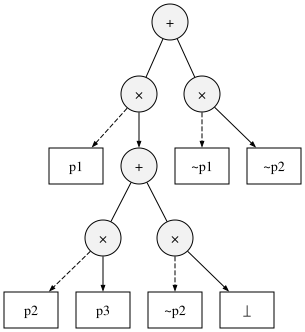

In [29]:
graphviz.Source(sdd_to_dot(F, litnamemap=var_map))

The idea then is that we can use such a representation to more efficiently compute WMC by linearly **evaluating** it (i.e., by assigning values to the variable/box nodes then applying the sum and product operations). More specifically, we can compute WMC exactly by doing the following:  

- **variable weights** For each node with a variable $\mathsf{p}$, assign weight $w(\mathsf{p})$ to that node.
- **negation weights** For each node with a variable $\neg\mathsf{p}$, assign weight $1 - w(\mathsf{p})$ to that node.
- **true/false weights** For true ($\top$) and false ($\bot$) nodes, assign weights 1 and 0, respectively.
- **evaluation** Once all variables are assigned, evaluate the circuit by applying the sum and product operations over those variable weights.

We call this circuit a **tractable representation** of our input formula given that WMC computation described above can be compute in linear time over the size of the circuit. **Importantly**, note that our main computational bottleneck still hasn't gone away, since the circuits we produce might still end up being exponentially larger than our input formula.  

- **<font color="red">Exercise 13</font>**: *Translate the circuit above back into a propositional formula and compare against the original formula and full DNF form of that formula.*

Below we show how to implement WMC over these sparse circuits using Pytorch. 

In [30]:
def sparse_circuit_WMC(node, weights): 
    """Computes WMC by linearly evaluating a circuit representation of formula
    
    Args: 
        node: 
            The input circuit node. 
        weights: 
            The variable weights.

    :see: https://github.com/pylon-lib/pylon/blob/47108cc6b25e94867b15b71d9726958295d64554/pylon/circuit_solver.py#L21
    """
    ## true/false nodes 
    if node.is_false(): 
        return 0.0 
    elif node.is_true(): 
        return 1.0
    
    ## variable nodes 
    elif node.is_literal() and node.literal > 0: 
        return weights[node.literal - 1] 
    elif node.is_literal() and node.literal < 0: 
        return 1.0 - weights[-node.literal - 1]
    
    ## sum/product nodes 
    elif node.is_decision():
        p = 0.0 
        for prime, sub in node.elements(): 
            p += sparse_circuit_WMC(prime, weights) * sparse_circuit_WMC(sub, weights)
        return p 

In [31]:
sparse_circuit_WMC(F, torch.tensor([0.45, 0.65, 0.34], requires_grad=True))

tensor(0.2920, grad_fn=<AddBackward0>)

- **<font color="red">Exercise 14</font>**: *Compute the semantic loss using the function above, and compute the weight gradients w.r.t that loss.*
- **<font color="red">Advanced Exercise 4</font>**: *Implement the sparse WMC traversal strategy above in log probability space.*

In [32]:
## gradient computation here. 

To ensure the correctness of our WMC function, we can compare it to the native WMC computation engine inside of pysdd.

In [33]:
f_wmc = F.wmc(log_mode=False)

## total number of models 
print(f"Total models (unweighted): {f_wmc.propagate()}")

### adding weights 
f_wmc.set_literal_weight(p1, 0.45) 
f_wmc.set_literal_weight(~p1, 1.0 - 0.45) 
f_wmc.set_literal_weight(p2, 0.65) 
f_wmc.set_literal_weight(~p2, 1.0 - 0.65) 
f_wmc.set_literal_weight(p3, 0.34) 
f_wmc.set_literal_weight(~p3, 1.0 - 0.34) 

### native WMC 
print(f"Pysdd WMC: {f_wmc.propagate()}")

Total models (unweighted): 3.0
Pysdd WMC: 0.29195000000000004


### Thinking about model errors

By using logic to study the semantics of loss functions and data, we can see the following: 

- **Data** contains lots of latent semantics. 
- **Existing losses** have an internal logic and semantics.
- Often, the semantics of those losses are limited, and do not explicitly account for the kinds of semantics we see in data.

For example, in [[**Berglund et al. 2024**]](https://arxiv.org/abs/2309.12288), they study what they call the *reversal curse*, or the empirical observation that models do not respect symmetries such as 

- *Tom Cruise's mother is Mary Lee Pfeiffer*
- *Mary Lee Pfeiffer's son is Tom Cruise*

A natural question is: *Should be surprised when models make these kinds of mistakes?* Based on the semantic analysis, I think there is reason **not** to be surprised, given that we can see more clearly that **models are not explicitly tuned** to respect such symmetries. Nonetheless, using the tools above, we can now turn such constraints explicitly into losses. 

---
## Part 3: Next-token evaluation with WMC

Perplexity scores whole sentences one at a time; it never says whether a prediction holds, or whether a constraint is satisfied. Instead, we can treat a token prediction as a proposition, $\mathcal{M}(x, w)$: *the model, on input $x$, predicts $w$* [[**Richardson et al. 2026**]](https://arxiv.org/abs/2609.13520). Then we take the token probabilities as weights and compute the WMC of a constraint.

In `symprog`, weights inside a program must be numbers, so we use placeholder weights (`0.5`), compile the constraint **symbolically**, and plug in the model's probabilities afterwards:

In [34]:
from symprog import Parser

@Parser(language="constraint")
def exclusive():
    a: 0.5; c: 0.5                     ## placeholder weights
    (a and not c) or (not a and c)     ## mutual exclusivity

wmc = exclusive.inference(symbolic=True).inference
wmc

a*(1 - c) + c*(1 - a)

In [35]:
wmc_fn = sp.lambdify(sorted(wmc.free_symbols, key=str), wmc)

wmc_fn(token_prob("A computer is not an airplane"),   ## a
       token_prob("A computer is an airplane"))       ## c

tensor(0.0054, grad_fn=<AddBackward0>)

Or compile the WMC directly into a PyTorch module (experimental in `symprog`):

In [36]:
import warnings; warnings.filterwarnings("ignore")

wmc_module = exclusive.tensorize()                     ## a PyTorch module

wmc_module(a=token_prob("A computer is not an airplane"),
           c=token_prob("A computer is an airplane"))

tensor(0.0054, grad_fn=<AddBackward0>)

The result is differentiable (note the `grad_fn`): `-torch.log` of it is the semantic loss, and `loss.backward()` updates the model. This raises **two problems** for evaluation:

1. The probabilities are tiny and **not Bernoulli** (a categorical over $\approx$ 50k tokens), even though the trend is right.
2. The WMC depends on the **structure** of the constraint. With the same probabilities, the weaker *at most one* constraint is satisfied almost by chance:

In [37]:
@Parser(language="constraint")
def at_most_one():
    a: 0.5; c: 0.5
    not (a and c)                      ## at most one

at_most_one_module = at_most_one.tensorize()
at_most_one_module(a=token_prob("A computer is not an airplane"),
                   c=token_prob("A computer is an airplane"))

tensor(1.0000, grad_fn=<AddBackward0>)

- **<font color="red">Question</font>**: *Why does the "at most one" constraint come out at (almost) 1.0, while "exactly one" is 0.0054? Write out the four worlds.*
- **<font color="red">Exercise</font>**: *Write `symprog` programs for paraphrase symmetry ($\mathcal{M}(a) \leftrightarrow \mathcal{M}(b)$) and negative information ($\neg\mathcal{M}(c) \land \neg\mathcal{M}(d)$) and evaluate them with the model's token probabilities.*

---
## Part 4: Problem 1: calibrating token probabilities

### Evaluating LMs for consistency

Even for the simple kinds of token-level constraints we have been considering, getting reliable measurements of consistency is difficult. This largely has to do with the large vocabulary size of models (i.e., each time a new token is predicted, it competes against sometimes 10s or 100s of thousands of other tokens), which will often make the token probabilities very small.  

Let's sketch this below using our example from before. I.e., with the following examples: 

- a: A computer is not an airplane.
- c: A computer is an airplane.

We want to measure the degree to which the model considers these to be mutually exclusive (focusing in particular on its prediction for the last token `airplane`). 

In [38]:
## positive example (no final period: the last token is `airplane`)
x = tokenizer("A computer is not an airplane", return_tensors="pt")
x_ids = x["input_ids"]
labels = x_ids.clone()
labels[:,:-1] = -100

## negative example
x_neg = tokenizer("A computer is an airplane", return_tensors="pt")
x_neg_ids = x_neg["input_ids"]
neg_labels = x_neg_ids.clone()
neg_labels[:, :-1] = -100

In [39]:
with torch.no_grad(): 
    output = model(input_ids=x_ids, labels=labels)
    neg_output = model(input_ids=x_neg_ids, labels=neg_labels)

We can here inspect the shape of the `logits` tensor to see the vocabulary size, which in this model is `49152` (recall that the output tensor has a structure of `|batch| x seq_length x vocab_size`, a good exercise is to implement these two forward calls using a single forward call with batch, which requires padding). 

In [40]:
batch, seq_len, vocab_size = output.logits.shape
print(f"Vocab size: {vocab_size}")

Vocab size: 49152


Intuitively, the `airplane` token in the first *positive example* competes with 49151 other tokens, many of which will be valid completions of the sequence. Using our trick of converting the loss back in a probability shown below will allow you to see that both probabilities are indeed small. 

In [41]:
airplane_prob     = torch.exp(-output.loss)
neg_airplane_prob = torch.exp(-neg_output.loss)

print(f"Probability of airplane in the positive sample: {airplane_prob}")
print(f"Probability of airplane in the negative sample: {neg_airplane_prob}")

Probability of airplane in the positive sample: 0.005392851307988167
Probability of airplane in the negative sample: 3.376591484993696e-05


Nonetheless, considering that `airplane` has so much competition, the resulting probability of `0.0054` seems quite high. In contrast, the probability of `airplane` in the second is considerably lower, so the model seems to be doing the right thing here. **The question is**: *can we adjust these probabilities to account for the large vocabulary size in order to make this pattern more clear?* Making the evaluation meaningful will rely on making such an adjustment *somehow*. The goal here is to sketch some possibilities.  

First to see the issue more clearly, below is the probability of our `1hot` constraint, which we might use as a metric. 

In [42]:
def compute_one_hot(a, b): 
    return (a * (1 - b)) + ((1 - a) * b)

print(f"Probability that Model satisfies 1hot: {compute_one_hot(airplane_prob, neg_airplane_prob)}")

Probability that Model satisfies 1hot: 0.005426253192126751


This probability is rather low, and it's unclear exactly what it is telling us. What we want to be able to say instead is something like: 

- **<font color="red">goal</font>** While the raw probabilities make this constraint low probability, considering the large size of the vocabulary and the gap between the two probabilities, the model does seem fairly consistent with this constraint. 

## **Probability Calibration** (challenge 1)

Let's consider how to integrate the vocabulary size into the equation to calibrate or adjust the probabilities. Doing this will rely on an important equality relating probability and [`odds`](https://en.wikipedia.org/wiki/Odds). Given a probability $p$, the odds is defined as:$$\text{Odds}_{p} := \frac{p}{1 - p}$$and is simply another way in which we can represent that probability. The `logit` function then takes the log of the odds, or $$\text{logit}(p) := \log \text{Odds}_{p} = \log \frac{p}{1 - p}$$and maps our initial probability (original in the range of $[0,1]$) into the entire real line. All of these values are simply different ways we can represent and reason about our probabilities and they each serve different purposes (e.g., the odds of a probability $0.9$ is equal to 9, which tell us that our expectation that an event will occur over 10 trials is 9 / 10). 

We can also translate between these different quantities as shown by the equality below:
$$p = \sigma(\text{logit}(p)) = \sigma \bigg(\log \frac{p}{1 - p} \bigg)$$which uses the well-known [`sigmoid` function](https://en.wikipedia.org/wiki/Sigmoid_function)$$\sigma(x) = \frac{1}{1 + e^{-x}}.$$

### Calibrating token probabilities 

Based on above, we see that the probability of a token can be written as$$P_{\text{llm}}(t) = \sigma\bigg( \log \frac{P_{\text{llm}}(t)}{1 - P_{\text{llm}}(t)}\bigg).$$Now let's define the calibrated form of that probability as follows:$$\hat{P}(t) = \sigma\bigg( \log \frac{P_{\text{llm}}(t)}{1 - P_{\text{llm}}(t)} + C \bigg)$$where we add a term $C$ to *shift* the log odds. Importantly, if we take $C = \log k$, this is equivalent to multiplying the odds by $e^{C}$or$$\sigma \bigg( \log \underbrace{e^{C} \cdot \frac{p}{1 - p}}_{\text{shifted odds}} \bigg).$$So for example, let's suppose we have a token that occurs 5 out of 50 times, the probability then is $$p = 5 / 50 = 0.1.$$ The odds here are then $1:9$ (i.e., out of 10 trials, we would expect to see the token 1 time). Now let's suppose that $9$ of those 50 tokens are the important ones (e.g., the ones that make up the most probability mass, the rest we can ignore) and we set $k=9$, then the odds becomes:$$e^{ \log 9} \cdot \frac{0.1}{0.9} \approx 1.0$$or that under this shift, we would now expect to see this token 10 out of 10 times. Now we can convert the log-odds back to probability:$$\hat{P}(t) = \sigma\bigg( \log 1.0 \bigg) \approx 0.5$$

This is sketched out below with different values of $k$. **Importantly**, as we increase $k$ (in this case, the number of *important* tokens), this steadily increases the probability of our original token.  

In [43]:
sigmoid = lambda x: 1 / (1 + math.exp(-x))

token_prob = 5. / 50
print(f"Raw odds: {token_prob / (1 - token_prob)}, {token_prob*10}:{(1 - token_prob)*10}")
print("\n")

a_odds_20 = math.exp(math.log(20)) * (token_prob / (1 - token_prob))
a_odds_9 = math.exp(math.log(9)) * (token_prob / (1 - token_prob))
a_odds_5 = math.exp(math.log(5)) * (token_prob / (1 - token_prob))
a_odds_1 = math.exp(math.log(1)) * (token_prob / (1 - token_prob))

print(f"Adjusted odds k=20: {a_odds_20}, new_prob={sigmoid(math.log(a_odds_20))}")
print(f"Adjusted odds k=9: {a_odds_9}, new_prob={sigmoid(math.log(a_odds_9))}")
print(f"Adjusted odds k=5: {a_odds_5}, new_prob={sigmoid(math.log(a_odds_5))}")
print(f"Adjusted odds k=1: {a_odds_1}, new_prob={sigmoid(math.log(a_odds_1))}")

Raw odds: 0.11111111111111112, 1.0:9.0


Adjusted odds k=20: 2.222222222222222, new_prob=0.689655172413793
Adjusted odds k=9: 1.0000000000000002, new_prob=0.5000000000000001
Adjusted odds k=5: 0.5555555555555555, new_prob=0.3571428571428571
Adjusted odds k=1: 0.11111111111111112, new_prob=0.10000000000000002


In [44]:
def calibrate(prob, C): 
    return sigmoid( math.log( prob / (1 - prob)) + C)

### Proposal 1: Factor in vocab size

Going back to our original case, the question is: *how should we set $C$* to meaningfully recalibrate the token probability and get $\hat{p}(\cdot)$? The first proposal is to set $C$ to the log of the number of tokens, or$$C_{\text{vocab}} = \log \text{|vocab|}.$$This would then give us new probabilities below for our original example: 

In [45]:
c_vocab = math.log(vocab_size) 

p1_airplane_prob     = calibrate(airplane_prob, c_vocab)
p1_neg_airplane_prob = calibrate(neg_airplane_prob, c_vocab)

print(f"New probability for pos airplane: {p1_airplane_prob}")
print(f"New probability for neg airplane: {p1_neg_airplane_prob}")

New probability for pos airplane: 0.996261775427368
New probability for neg airplane: 0.6240203213313094


The idea then is that we can plug in these new values to evaluate our constraint: 

In [46]:
print(f"New constraint probability: {compute_one_hot(p1_airplane_prob, p1_neg_airplane_prob)}")

New constraint probability: 0.3769069102941035


This certainly produces a larger and more meaningful number. Using the vocab size also has the following advantages: 

- It is easy to evaluate.
- The vocabulary size stays fixed across multiple examples.

On the negative side, it will often make probabilities very big and will saturate easily.  

### Proposal 2: Factor in top-k tokens

In order to make the probabilities not get too large and saturate, another solution is to limit the count of tokens to the number of most probable tokens. The question then is: *how do we determine the number of most important tokens?*

One proposal is simply to set this to a particular number as we did above, e.g., $k=50$. Below shows this: 

In [47]:
k = 50 
c_topk = math.log(k) 

p2_airplane_prob     = calibrate(airplane_prob,c_topk)
p2_neg_airplane_prob = calibrate(neg_airplane_prob, c_topk)

print(f"New probability for pos airplane: {p2_airplane_prob}")
print(f"New probability for neg airplane: {p2_neg_airplane_prob}")
print("\n")

print(f"New constraint probability: {compute_one_hot(p2_airplane_prob, p2_neg_airplane_prob)}")

New probability for pos airplane: 0.21328268474999432
New probability for neg airplane: 0.001685506946699845


New constraint probability: 0.21424921280318032


This approach has the advantage of making it harder to saturate, however it requires coming up with a fixed value $k$, which might not be appropriate across different examples. 

### Proposal 3: Factor in top-p tokens

To make this value more dynamic to each situation, we can consider the number of token that constitute the top $p$ percentage of the probability mass. This is related to the [*nucleus*](https://en.wikipedia.org/wiki/Top-p_sampling) of the distribution, and commonly used to truncate the distribution during decoding. 

To implement this we will need more details as below: 

In [48]:
with torch.no_grad():
    full_output = model(input_ids=x_ids)
    neg_full_output = model(input_ids=x_neg_ids)

# logits at the last position (predicting "airplane")
logits = full_output.logits[0, -2, :]  # position before final token
neg_logits = neg_full_output.logits[0, -2, :]

# recompute the distribution 
probs = torch.softmax(logits, dim=-1)
neg_probs = torch.softmax(neg_logits, dim=-1)

## token id for `airplane`
airplane_token_id = x_ids[0, -1].item()

## how to compute the nucleus, consider number of tokens in top 0.95 of the distribution 
def nucleus_size(probs, p=0.95):
    sorted_probs, _ = torch.sort(probs, descending=True)
    cumsum = torch.cumsum(sorted_probs, dim=-1)
    return (cumsum < p).sum().item() + 1

In [49]:
nuc_pos = nucleus_size(probs)
nuc_neg = nucleus_size(neg_probs)
c_nuc_pos = math.log(nuc_pos)
c_nuc_neg = math.log(nuc_neg)

p3_airplane_prob     = calibrate(airplane_prob,c_nuc_pos)
p3_neg_airplane_prob = calibrate(neg_airplane_prob, c_nuc_neg)

print(f"New probability for pos airplane: {p3_airplane_prob}")
print(f"New probability for neg airplane: {p3_neg_airplane_prob}")
print("\n")

print(f"New constraint probability: {compute_one_hot(p3_airplane_prob, p3_neg_airplane_prob)}")

New probability for pos airplane: 0.851556578784022
New probability for neg airplane: 0.014377635283796281


New constraint probability: 0.8414474742412703


This seems to produce a more interpretable probability. It has the disadvantage, however, or needing to set a nucleus parameter $p$, and makes the number of tokens different across examples. 

### Proposal 4: Entropy

The last proposal is to set $C$ to the entropy of the token distribution (we can also consider the entropy of the nucleus). 

In [50]:
def entropy(probs):
    log_probs = torch.log(probs + 1e-12)
    return -(probs * log_probs).sum().item()

def nucleus_entropy(probs, p=0.95):
    sorted_probs, sorted_idx = torch.sort(probs, descending=True)
    cumsum = torch.cumsum(sorted_probs, dim=-1)
    mask = cumsum < p
    mask[0] = True  # always include top token
    nuc_probs = sorted_probs[mask]
    nuc_probs = nuc_probs / nuc_probs.sum()  # renormalize
    log_probs = torch.log(nuc_probs + 1e-12)
    return -(nuc_probs * log_probs).sum().item()

h_pos = entropy(probs)
h_neg = entropy(neg_probs)

p4_airplane_prob     = calibrate(airplane_prob,h_pos)
p4_neg_airplane_prob = calibrate(neg_airplane_prob, h_neg)

print(f"Size of effective live region, pos airplane: {np.exp(h_pos)}")
print(f"Size of effective live region, neg airplane: {np.exp(h_neg)}")
print(f"New probability for pos airplane: {p4_airplane_prob}")
print(f"New probability for neg airplane: {p4_neg_airplane_prob}")
print("\n")

print(f"New constraint probability: {compute_one_hot(p4_airplane_prob, p4_neg_airplane_prob)}")


print("\nEntropy of nucleus")
h_nuc_pos = nucleus_entropy(probs)
h_nuc_neg = nucleus_entropy(neg_probs)

p5_airplane_prob     = calibrate(airplane_prob,h_nuc_pos)
p5_neg_airplane_prob = calibrate(neg_airplane_prob, h_nuc_neg)
print(f"New probability for pos airplane: {p5_airplane_prob}")
print(f"New probability for neg airplane: {p5_neg_airplane_prob}")

print(f"New constraint probability: {compute_one_hot(p5_airplane_prob, p5_neg_airplane_prob)}")

Size of effective live region, pos airplane: 367.3260965541814
Size of effective live region, neg airplane: 56.33128135834348
New probability for pos airplane: 0.6657391937940348
New probability for neg airplane: 0.0018985301207227543


New constraint probability: 0.6651098720908302

Entropy of nucleus
New probability for pos airplane: 0.5778555689939441
New probability for neg airplane: 0.001285398870205341
New constraint probability: 0.5776554180730961


### Proposal 5 and a bigger problem for evaluation... 

It is important to emphasize again that the 1-hot constraint, and any metric we derive from it, does not tell us which input is *correct* or *incorrect* it just says that the two sentences should be different in complementary ways. For example, `airplane` should have a high score in one sentence (e.g., it should be in the nucleus of the distribution) and low in the other, but we don't care which sentence has a high/low score (evaluating which one is correct or factual is a different matter). 

**<font color="red">The problem</font>**: Let's suppose that `airplane` has a low score (e.g., doesn't show up in the nucleus of the distribution) in **both** cases. A question is: *what does this tell us?*  Unfortunately, such a case only tells us that both instances are likely out-of-distribution; when we use lots of synthetic data, this is often going to happen. The fundamental problem here is that we cannot tease apart a model's knowledge and its training distribution. 

**One solution to this problem** is to filter data to instances where one of the trigger words has a high score, which will control for the influence of the data distribution. A downside of this is that it requires creating model-specific evaluation sets, since models will differ in their behavior (the degree to which models disagree might be worthwhile to measure seperately). 

Another metric that gets around this is the **entropy** of the calibrated probabilities or (slightly differently) the entropy of the interpretations of the one-hot constraint. For example, suppose that we have the following probabilities: 

```
P(airplane_1) = 5e-6
P(airplane_2) = 3e-6
```
We an compute [(conditional) entropy](https://en.wikipedia.org/wiki/Entropy_(information_theory)) over the two possible interpretations $I$ of our constraint $\textsf{F}_{\text{1hot}}$:
```
i1 = P(airplane_1) * (1 - P(airplane_1))
i2 = (1 P(airplane_1)) * P(airplane_1)
```
shown below. 

In [51]:
## interpretation scores
i1 = float(5e-6) * (1 - float(3e-6))
i2 = (1 - float(5e-6)) * float(3e-6)

## normalized over full interpretations
i1_normalized = i1 / (i1 + i2)
i2_normalized = i2 / (i1 + i2)

## entropy calculation H(I | F)
interp_probs = [i1_normalized, i2_normalized]
constraint_entropy = -np.sum([q * np.log(q) for q in interp_probs])

print(f"Constraint entropy: {constraint_entropy}")

Constraint entropy: 0.6615629987071042


In this entropy formulation, if two probabilities are low, they will likely have high entropy between them, so this metric implicitly penalizes models for these out-of-distribution cases. 

---
## Part 5: Problem 2: comparing against chance

### Challenges for finding good constraints

When deciding what kinds of constraints to evaluate, one also runs into problems involving the inherent informativeness of a given constraint. For example, supposing we have the following constraint: 

$$F := \textsf{p}_{1} \to \textsf{p}_{2}$$ 

If we consider the WMC of $F$, we can see below that $F$ is true in 3/4 intrepretations: 

|        Interpretation         |  $I \in \mathcal{M}(\textsf{F})$  | $w(I)$ | 
:-------------|:-----:|:-----|
| $I_{1} = \{ \mathsf{p}_{1}, \mathsf{p}_{2} \}$ | yes | $w(\mathsf{p}_{1})w(\mathsf{p}_{2})$
| $I_{2} = \{ \neg\mathsf{p}_{1}, \mathsf{p}_{2} \}$      |   yes | $(1 - w(\mathsf{p}_{1}))w(\mathsf{p}_{2})$
| $I_{3} = \{ \mathsf{p}_{1}, \neg \mathsf{p}_{2} \}$      |    no | $w(\mathsf{p}_{1})(1 - w(\mathsf{p}_{2}))$
| $I_{4} = \{ \neg \mathsf{p}_{1}, \neg \mathsf{p}_{2} \}$      |    yes | $(1 - w(\mathsf{p}_{1}))(1 - w(\mathsf{p}_{2}))$

In other words, even if the individual prediction probabilities are not high, the WMC of that formula, which we use as a metric of consistency, will always be high given that we are always summing many probabilities. This begs the question: **Can we account for this somehow when computing the WMC metric?**

### Binary thresholding using a uniform prior 

As a concrete example, suppose that we set $w(p_{1}) = w(p_{2}) = 0.5$, notice that the WMC of $F$ is equal to 0.75. Given that having a weight of $0.5$ for all variables is maximally uninformative, we therefore can say that a WMC count indicates that a constraint is satisified if and only if it is higher than 0.75

Formally, define $\text{WMC}_{0}(F)$ as the weighted model count of $F$ under uniform weights. Observe that: 
$$\text{WMC}_{0}(F) = \frac{\mid \text{models of F}  \mid}{2^{\mid \text{number of variables} \mid}}$$
We can then define a binary 0/1 score for each instance $F_{d}$ (i.e., a constraint $F$ applied to a particular example $d$) as follows;
$$\text{Score}(F_{d}; w) = 1 \text{ if } \text{WMC}(F_{d}; w) > \text{WMC}_{0}(F) \,\, 0 \text{ otherwise }$$
then for a dataset $D$, we can aggregate this into an overall accuracy score: 
$$\text{Consistency}(F, D) = \frac{\sum_{d \in D} \text{Score}(F_{d}; w)}{| D |}.$$

### A relaxed form of the threshold  

The binary score is still a bit crude. For example, we can can do better than 0.75 by simply setting $w(p_{1}) = w(p_{2}) = 0.51$ since: 
$$\text{WMC}(F; w) = 1 - \text{WMC}(\neg F; w) = 1 - (0.51 * (1 - 0.51)) = 0.7501.$$
What would therefore be helpful is to have an extra metric that **tells us how far away we are from this uniformative prior**. This can be achieved by computing the below quantity: 
$$\text{Score'}(F; w) = \frac{\text{WMC}(F;w) - \text{WMC}_{0}(F)}{1 - \text{WMC}_{0}(F)}$$

For example for our example above: 
$$\text{Score'} = \frac{0.7501 - 0.75}{0.25} = 0.00039999999999995595$$

where $0$ tells us that it is exactly at the uninformative prior. 


### Determining the informativeness of a constraint in general: an information-theoretic view

One natural question is: independent of our model, **can we in characterize constraints in interms of their inherent information content?** If we had a metric for this, this would give us a way to reason about whether a constraint is even worthwhile to use for evaluation (or, as we discuss below, for training). 

This can be achieved by defining the information content of $F$ (where below we use $m$ to denote the total number of models of $F$ and $n$ the total number of variables as above): 
$$I(F) = -\log_{2} \underbrace{\frac{m}{2^{n}}}_{\text{WMC}_{0}(F)} = n - \log_{2} m.$$

This simply tells us the amount of bits a given constraint $F$ encodes. As another framing: If I told you that $F$ is true and sampled uniformly from the set of $2^n$ models, this tells us how[surprised](https://en.wikipedia.org/wiki/Information_content) you would be to see a model that satisfies $F$? If $F$ is a tautology (i.e.,  it is true in all models), then the value is $0$. 

**<font color="red">Exercise</font>**: Based on this, compare the different constraints that we have been discussing.

**<font color="red">Question</font>**: Consider the constraint for standard MLE. Is it highly informative? Might this explain it's success for learning?  

### Determining if a constraint has any hope of helping training 

The informativeness of a constraint is, of course, deeply connected to learning. Recalling that the semantic loss for a formula $F$ is: 
$$\ell_{sl}(F) = -\log \text{WMC}(F; w)$$
if we consider the gradient w.r.t to our language model parameters $\theta$ we can see that: 
$$\frac{\partial \ell_{sl}(F)}{\partial \theta} = - \frac{1}{\text{WMC}(F; w)} \frac{\partial \text{WMC}(F; w)}{\partial \theta}$$
or that the mangitude of the gradient signal is controlled by $\text{WMC}(F)$. 

**example** Below is an example and reminder of how to compute gradients using pretend model weights $\theta$ (containing a single probability) and a loss for the formula $$F := m$$
or a formula involve a single prediction `m`. In this case: 
$$\text{WMC}(F; w) = w(w)$$
and it is easy to see that: 
$$\frac{\partial \text{WMC}(F; w)}{\partial w(m)} = \frac{\partial w(m)}{\partial w(m)} = 1$$
meaning that in this case: 
$$\frac{\partial \ell_{sl}(F)}{\partial \theta} = - \frac{1}{w(m)}.$$
as shown below. 

**<font color="red">Exercise</font>**: Ensure that you understand the math here. 

In `symprog`, the placeholder weights of `0.5` give $\text{WMC}_{0}$ directly. Combining both fixes (calibrated probabilities, compared against chance) for our example:

In [52]:
wmc0_exclusive   = exclusive.inference().inference.item()     ## placeholder weights 0.5 -> WMC_0
wmc0_at_most_one = at_most_one.inference().inference.item()

def score(wmc, wmc0):                     ## fraction of the possible improvement over chance
    return (wmc - wmc0) / (1 - wmc0)

p_a = calibrate(airplane_prob, h_nuc_pos)            ## calibrated with the nucleus entropy (Part 4)
p_c = calibrate(neg_airplane_prob, h_nuc_neg)

for name, module, wmc0 in [("exactly one", wmc_module, wmc0_exclusive),
                           ("at most one", at_most_one_module, wmc0_at_most_one)]:
    w = module(a=torch.tensor(p_a), c=torch.tensor(p_c)).item()
    print(f"{name}: WMC_0 = {wmc0:.2f}, calibrated WMC = {w:.4f}, score = {score(w, wmc0):.3f}, "
          f"I(F) = {-math.log2(wmc0):.3f} bits")

exactly one: WMC_0 = 0.50, calibrated WMC = 0.5777, score = 0.155, I(F) = 1.000 bits
at most one: WMC_0 = 0.75, calibrated WMC = 0.9993, score = 0.997, I(F) = 0.415 bits


In [53]:
## pretend model with a single probability/variable
w = torch.tensor([0.9], requires_grad=True)

### fake prediction `m` 
m_pred = w[0]

model_loss = -torch.log(w[0]) ## semantic loss , WMC(m) = w[0]  
## backprop
model_loss.backward() 

print(f"Grad for theta: {w.grad}")

wmc = 0.9 ## probability of prediction `m`, single model where `m=true`
first_term  = 1 / 0.9 ## 1 / WMC(F; w)
second_term = 1 ##  (\partial m) / (\partial m) = 1 ## uses some calculus   
print(f"manual gradient: {- first_term * second_term}")

Grad for theta: tensor([-1.1111])
manual gradient: -1.1111111111111112


Interestingly, for any constraint $F$, the following then holds: 
$$\left\Vert \frac{\partial \ell_{sl}(F; w)}{\partial \theta} \right\Vert  = \frac{1}{\text{WMC}(F; w)} \left\Vert \frac{\partial \text{WMC}(F; w)}{\partial \theta} \right\Vert$$
In the case where the model does at least as well as the uninformed baseline, the following then holds, which puts an upper bound on how much the constraint can contribute to the gradient: 
$$\left \Vert \frac{\partial \ell_{sl}(F; w)}{\partial \theta} \right\Vert \leq \frac{1}{\text{WMC}_0(F)} \left\Vert\frac{\partial \text{WMC}(F; w)}{\partial \theta} \right\Vert \leq 2^{I(F)} \left\Vert\frac{\partial \text{WMC}(F; w)}{\partial \theta} \right\Vert \hspace{1cm} (\text{whenever } \text{WMC}(F; w) \geq \text{WMC}_{0}(F))$$
which shows how gradient signal grows exponentially with the informativeness of $F$. 

Below we show how to **compute a gradient norm** for the standard pre-training loss using a real example from the top of the notebook. 

In [54]:
model.zero_grad()
loss = model(input_ids=x_ids, labels=labels).loss ## forward inference and CE loss 

## run backpropagation 
loss.backward()  ## backprop CE loss 

grad_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(), max_norm=float('inf')
)

print(f"Gradient norm: {grad_norm}")

Gradient norm: 79.5


**<font color="red">Exercise</font>**: This norm assumes an L2 norm. Compute this manually (i.e., without the helper function used here)?

**<font color="red">Exercise</font>**: Compute the gradnorm for our other losses above. 

#### An interesting identity 
One useful identity involves first defining: 
$$A(F; w) = \frac{\text{WMC}_{0}(F)}{\text{WMC}(F; w)}$$
which measures how much worse or better our model is versus an uninformed model. If we then divide by $\text{WMC}_{0}(F)$ we see that: 
$$\frac{A(F; w)}{\text{WMC}_{0}(F)} = \frac{1}{\text{WMC}(F; w)}$$ meaning that
$$\begin{align*}\frac{\partial \ell_{sl}(F; w)}{\partial \theta} &= - \frac{A(F; w)}{\text{WMC}_{0}(F)}\frac{\partial \text{WMC}(F; w)}{\partial \theta} \\ &= - A(F; w)\frac{1}{\text{WMC}_{0}(F)}\frac{\partial \text{WMC}(F; w)}{\partial \theta} \\ &= - A(F; w)2^{I(F)}\frac{\partial \text{WMC}(F; w)}{\partial \theta} \end{align*}.$$

This shows how we can decompose the gradient signal into the following three pieces w.r.t a constraint $F$: 
- $A(F; w)$, which tells us how well the model is already doing on this constraint; 
- $2^{I(F)}$, which tells us about about the inherent capacity of that constraint to provide signal;
-  $\frac{\partial \text{WMC}(F; w)}{\partial \theta}$, which tells us what update the model will actually do and the local training pressure. 

We can check this identity numerically for mutual exclusivity, using the calibrated probabilities as the weights:

In [55]:
w = torch.tensor([p_a, p_c], requires_grad=True)
wmc_val = wmc_module(a=w[0], c=w[1])
loss = -torch.log(wmc_val)                                        ## semantic loss

grad_loss = torch.autograd.grad(loss, w, retain_graph=True)[0]
grad_wmc  = torch.autograd.grad(wmc_val, w)[0]

A = wmc0_exclusive / wmc_val.item()                               ## fit vs. chance
I_F = -math.log2(wmc0_exclusive)                                  ## informativeness, in bits

print(f"gradient of the semantic loss: {grad_loss}")
print(f"-A * 2^I(F) * grad WMC:        {-A * 2 ** I_F * grad_wmc}")

gradient of the semantic loss: tensor([-1.7267,  0.2696])
-A * 2^I(F) * grad WMC:        tensor([-1.7267,  0.2696])


### An argument for why cross-entropy is so effective (one possible reading) 

Given our definition of informativeness: 
$$I(F) = -\log_{2} \frac{| \text{Mods}(F) |}{2^{| \text{\# vars } n |}} $$
given that the minimal number of models for any satisfiable formula $F$ is 1, then it follows that: 
$$\forall F. \, I(F) \leq -\log_{2} \frac{1}{2^n} = n$$
Since cross-entropy is just a conjunction of $n$ variables, it is maximally informative given that it carries exactly $n$ bits of uniform under the uniform baseline, i.e., 
$$I(\bigwedge_{i}^{n} \mathsf{p}_{i}) = n$$


Hence, it **may** contribute more gradient signal than most other losses. This is only a partial and debatable answer to the puzzle: the update direction matters, the uniform (fair-coin) baseline is artificial for categorical token predictions, and the bound above only holds when $\text{WMC}(F; w) \geq \text{WMC}_{0}(F)$.

- **<font color="red">Question</font>**: *For raw next-token probabilities, does the likelihood formula satisfy $\text{WMC}(F; w) \geq \text{WMC}_{0}(F)$? (hint: compare the average token probability to $0.5$, or use the perplexities from Part 1).* 

### Variable behavior in the gradient 

We can also look at the gradients to see various spurious patterns or shortcuts that control the behavior of individual variables. For example, if we take the constraint: 
$$F := a \to b$$
we can see the following w.r.t a: 
$$\frac{\partial \ell_{sl}(F)}{\partial w(a)} = \frac{1 - w(B)}{1 - w(A)(1 - w(B))}$$
which puts pressure on the model to minimize $w(A)$. 

Below shows a toy example. 

In [56]:
w = torch.tensor([0.4, 0.6], requires_grad=True) ## probabilities 
a, b = w 

sl = -torch.log(1 -  (a * (1 - b))) ## WMC(F) = 1 - WMC(not F)
sl.backward() 

print(f"Resulting gradient: {w.grad}")
print(f"Equation above for a (sanity): {(1 - 0.6)/ (1 - (0.4 * (1 - 0.6)))}")

## hypothetical gradient update 
new_w = w - w.grad

print("================")
print(f"Initial probs: {torch.sigmoid(w)}")
print(f"new probs: {torch.sigmoid(new_w)}")

Resulting gradient: tensor([ 0.4762, -0.4762])
Equation above for a (sanity): 0.4761904761904762
Initial probs: tensor([0.5987, 0.6457], grad_fn=<SigmoidBackward0>)
new probs: tensor([0.4810, 0.7458], grad_fn=<SigmoidBackward0>)


**<font color="red">Exercise</font>**: Turn the example above into a SGD style loop to see what happens to the probability of a. 

**<font color="red">helpful tool</font>**: If you are bad at math like me, you can also solve these equations in sympy as below: 

In [57]:
a, b = sp.symbols("a b", positive=True, real=True)
f = -sp.log(1 - (a * (1 - b)))

## solve partial derivatives w.r.t a, should yield same equation.
f_a = sp.diff(f, a)

print(f_a)
print(f_a.subs({a : 0.4, b : 0.6}))

-(b - 1)/(-a*(1 - b) + 1)
0.476190476190476


**Contour maps** One way to visualize the behavior of the variables is to draw a loss landscape as below.  

Matplotlib is building the font cache; this may take a moment.


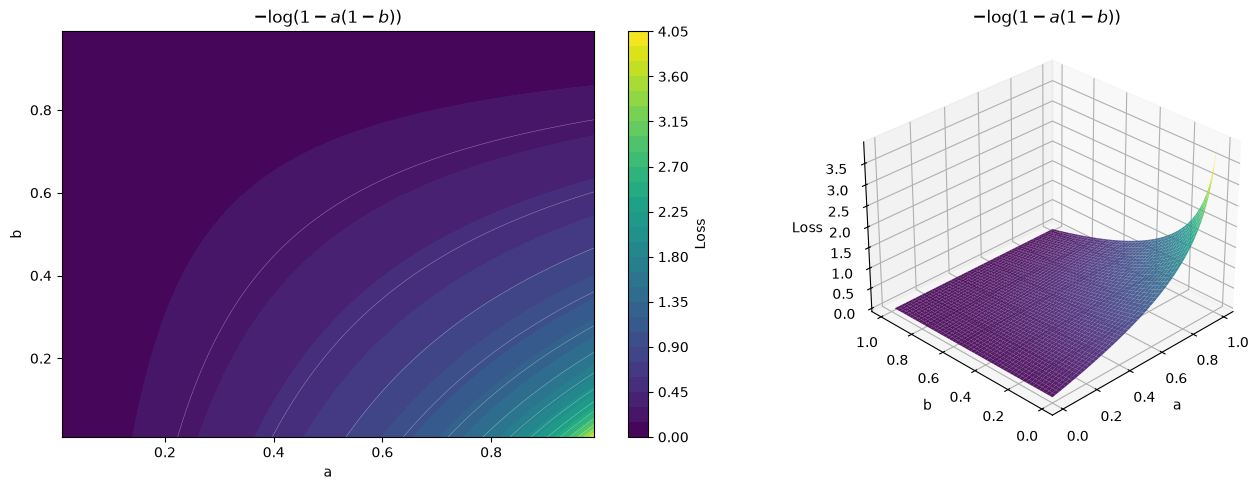

In [58]:
import matplotlib.pyplot as plt

a = np.linspace(0.01, 0.99, 200)
b = np.linspace(0.01, 0.99, 200)
A, B = np.meshgrid(a, b)

SL = -np.log(1 - A * (1 - B))
#SL = -np.log(A*(1-B) + (1-A)*B)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Contour plot
cp = axes[0].contourf(A, B, SL, levels=30, cmap="viridis")
axes[0].contour(A, B, SL, levels=15, colors="white", linewidths=0.3, alpha=0.5)
fig.colorbar(cp, ax=axes[0], label="Loss")
axes[0].set_xlabel("a")
axes[0].set_ylabel("b")
axes[0].set_title(r"$-\log(1 - a(1 - b))$")

# 3D surface
ax3d = fig.add_subplot(1, 2, 2, projection="3d")
axes[1].remove()
ax3d.plot_surface(A, B, SL, cmap="viridis", edgecolor="none", alpha=0.9)
ax3d.set_xlabel("a")
ax3d.set_ylabel("b")
ax3d.set_zlabel("Loss")
ax3d.set_title(r"$-\log(1 - a(1 - b))$")
ax3d.view_init(elev=30, azim=-135)

plt.tight_layout()
plt.show()

- **<font color="red">Exercise</font>**: *Compute these loss plots for our other losses.*